# CVAE — Arquitectura A (Sistema Completo)

Una muestra = un dia completo del sistema electrico argentino: **x** es un vector de 528 dimensiones (22 provincias x 24 horas) y **c** combina calendario y clima diario por provincia, ambos disponibles el dia evaluado sin usar informacion futura.

El modelo aprende correlaciones entre provincias implicitamente a traves de la estructura del vector x — no recibe ninguna etiqueta de provincia.

**Nota sobre indicadores socioeconomicos**: aunque `c_condiciones_diarias.csv` incluye columnas de poblacion, PBG per capita, participacion industrial y superficie por provincia, el preprocessing corregido de CVAE-A las excluye explicitamente. Esta arquitectura usa solo calendario + clima como vector de condiciones; los indicadores socioeconomicos quedan reservados para CVAE-B, donde cada muestra es una provincia-dia y esas variables si varian entre muestras.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import pickle
import json
import matplotlib.pyplot as plt
import torch

project_root = Path.cwd().parent
sys.path.append(str(project_root / 'src'))

from cvae import CVAE
from train_cvae import train, set_seed
from evaluate_cvae import (
    full_evaluation, generate_scenarios,
    metrics_by_month_a, temperature_sweep, select_temperature,
)

SPLITS_DIR  = project_root / 'data' / 'splits'
RESULTS_DIR = project_root / 'results' / 'cvae_a'
RESULTS_DIR.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

Device: cpu


## 1. Cargar datos

In [3]:
X_train = np.load(SPLITS_DIR / 'X_train.npy')
X_val   = np.load(SPLITS_DIR / 'X_val.npy')
X_test  = np.load(SPLITS_DIR / 'X_test.npy')
C_train = np.load(SPLITS_DIR / 'C_train.npy')
C_val   = np.load(SPLITS_DIR / 'C_val.npy')
C_test  = np.load(SPLITS_DIR / 'C_test.npy')

dates_val  = np.load(SPLITS_DIR / 'dates_val.npy',  allow_pickle=True)
dates_test = np.load(SPLITS_DIR / 'dates_test.npy', allow_pickle=True)

with open(SPLITS_DIR / 'x_scaler.pkl', 'rb') as f:
    x_scaler = pickle.load(f)

print(f'X_train: {X_train.shape}, C_train: {C_train.shape}')
print(f'x_dim={X_train.shape[1]}, c_dim={C_train.shape[1]}')
print(f'x_scaler ajustado sobre {x_scaler.n_samples_seen_} dias de train '
      f'(coincide con X_train: {x_scaler.n_samples_seen_ == len(X_train)})')

X_train: (1457, 528), C_train: (1457, 267)
x_dim=528, c_dim=267
x_scaler ajustado sobre 1457 dias de train (coincide con X_train: True)


**Verificacion de leakage**: el `x_scaler` se ajusta exclusivamente sobre los dias de `X_train` (se confirma arriba comparando `n_samples_seen_` contra `len(X_train)`); `X_val`/`X_test` solo se transforman con ese scaler ya ajustado, nunca se re-ajusta. Los hiperparametros de este notebook (`CONFIG`, arquitectura de la red, y mas adelante la temperatura de generacion) se eligen mirando metricas de validacion; test solo se evalua una vez, en la seccion 6.

## 2. Definir y entrenar el modelo

Arquitectura MLP mediana como punto de partida.
Los hiperparametros se eligen sobre val — no sobre test.

In [4]:
CONFIG = {
    'lr':            1e-3,
    'batch_size':    256,
    'max_epochs':    300,
    'patience':      30,
    'beta':          0.01,
    'warmup_epochs': 50,
    'free_bits':     2.0,
    'seed':          42,
    'device':        DEVICE,
}

model_a = CVAE(
    x_dim=X_train.shape[1],
    c_dim=C_train.shape[1],
    hidden_dims=[64, 64],
    latent_dim=32,           # ← de 16 a 32
)
print(model_a)

CVAE(
  (encoder): Encoder(
    (net): Sequential(
      (0): Linear(in_features=795, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (mu): Linear(in_features=64, out_features=32, bias=True)
    (logvar): Linear(in_features=64, out_features=32, bias=True)
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=299, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (out): Linear(in_features=64, out_features=528, bias=True)
  )
)

In [5]:
history_a = train(
    model_a,
    X_train, C_train,
    X_val,   C_val,
    config=CONFIG,
    save_path=RESULTS_DIR / 'cvae_a_checkpoint.pt',
)

Training on cpu | x_dim=528 | c_dim=267 | latent_dim=32
Train: 1457 samples | Val: 366 samples
------------------------------------------------------------
Epoch 001 | beta=0.000 | train=1.0617 (r=1.0613 kl=2.0000) | val=1.1847 (r=1.1843 kl=2.0000)
Epoch 010 | beta=0.002 | train=0.3689 (r=0.3649 kl=2.0299) | val=0.5042 (r=0.5001 kl=2.0251)
Epoch 020 | beta=0.004 | train=0.2442 (r=0.2358 kl=2.0941) | val=0.3682 (r=0.3599 kl=2.0840)
Epoch 030 | beta=0.006 | train=0.1928 (r=0.1802 kl=2.1020) | val=0.3094 (r=0.2967 kl=2.1063)
Epoch 040 | beta=0.008 | train=0.1572 (r=0.1404 kl=2.0999) | val=0.2603 (r=0.2435 kl=2.0992)
Epoch 050 | beta=0.010 | train=0.1383 (r=0.1174 kl=2.0870) | val=0.2352 (r=0.2142 kl=2.0927)
Epoch 060 | beta=0.010 | train=0.1252 (r=0.1044 kl=2.0757) | val=0.2098 (r=0.1889 kl=2.0831)
Epoch 070 | beta=0.010 | train=0.1149 (r=0.0941 kl=2.0731) | val=0.1987 (r=0.1779 kl=2.0830)
Epoch 080 | beta=0.010 | train=0.1068 (r=0.0861 kl=2.0699) | val=0.1911 (r=0.1703 kl=2.0811)
Epoch 0

## 3. Curvas de entrenamiento

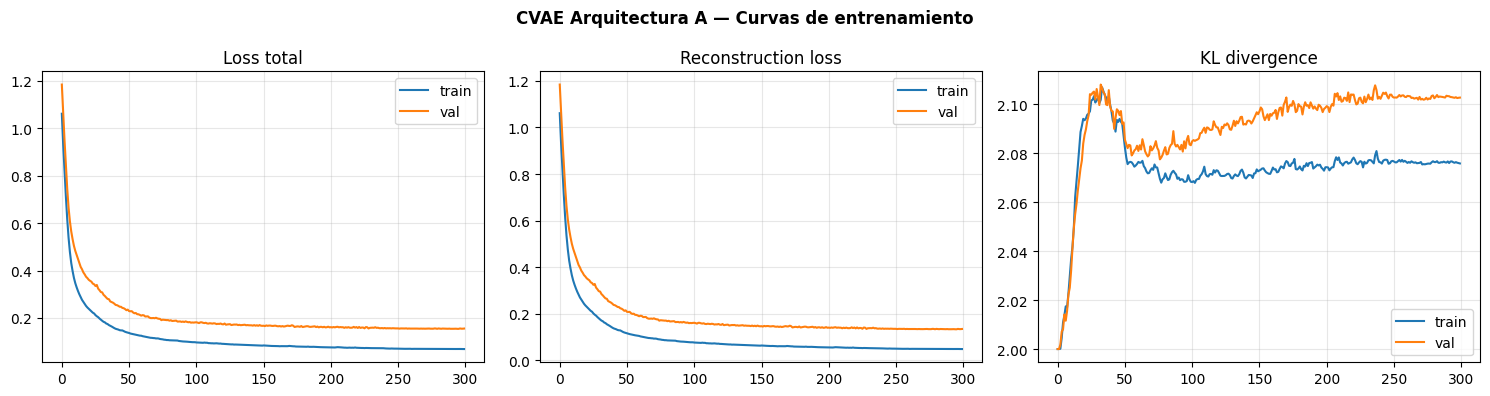

Mejor val loss: 0.1540


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history_a['train_loss'], label='train')
axes[0].plot(history_a['val_loss'],   label='val')
axes[0].set_title('Loss total')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_a['train_recon'], label='train')
axes[1].plot(history_a['val_recon'],   label='val')
axes[1].set_title('Reconstruction loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(history_a['train_kl'], label='train')
axes[2].plot(history_a['val_kl'],   label='val')
axes[2].set_title('KL divergence')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('CVAE Arquitectura A — Curvas de entrenamiento', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_a_training.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Mejor val loss: {history_a["best_val_loss"]:.4f}')

## 4. Evaluacion en validacion

In [7]:
metrics_val_a, scenarios_val_a = full_evaluation(
    model_a, X_val, C_val, x_scaler,
    n_scenarios=500, device=DEVICE, architecture='A'
)

print('Metricas en validacion:')
print(f'  MAE global:      {metrics_val_a["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_val_a["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_val_a["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_val_a["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_val_a["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_val_a["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_val_a["mmd"]:.4f}')

Generando 500 escenarios para 366 muestras...
Calculando metricas...
Metricas en validacion:
  MAE global:      55.1 MWh
  RMSE global:     147.9 MWh
  MAPE energia:    5.01%
  Coverage P5-P95: 77.8%
  Sharpness:       180.2 MWh
  Diversity ratio: 0.420
  MMD:             0.0055


In [8]:
metrics_val_a['per_province']

,provincia,mae_mwh,coverage,sharpness
0,buenos_aires,501.5,84.0,1822.8
1,santa_fe,130.5,76.4,404.5
2,chubut,97.9,58.8,193.1
3,cordoba,92.6,75.4,274.9
4,mendoza,42.1,75.7,130.0
5,chaco,36.7,81.7,128.4
6,entre_rios,35.8,77.8,112.7
7,misiones,35.2,85.6,129.1
8,tucuman,32.3,78.1,106.2
9,corrientes,29.5,80.1,100.7


**Diagnostico de subcobertura**

El coverage P5-P95 en validacion es de 77.8%, todavia por debajo del ~90% buscado. Esto indica que el modelo **subestima la incertidumbre**: genera bandas mas angostas de lo que la variabilidad real del sistema justificaria, por lo que el dato real cae fuera de la banda con mas frecuencia de la esperada (idealmente ~10% de las veces, aca ronda el 22%). El `diversity_ratio` de ~0.42 confirma el mismo diagnostico desde otro angulo: el desvio de los escenarios generados es menos de la mitad del desvio real.


**Comparacion contra Conditional KDE**

Tomando la configuracion final del KDE condicional (seleccionada por criterio generativo en `provincias/results/conditional_kde_baseline/metrics_overall.csv`): coverage 84.6%, sharpness 354.7 MWh, RMSE de perfil medio 253.5 MWh. Contra el CVAE-A corregido en test (coverage 86.4%, sharpness 270.2 MWh, RMSE 168.5 MWh), el patron cambia respecto del run anterior: **el CVAE-A aprende mejor el perfil medio y tambien logra una cobertura P5-P95 levemente mayor con bandas mas estrechas**. En estas metricas agregadas, el modelo corregido queda por encima del KDE condicional; la lectura fina igual conviene hacerla junto con el analisis por provincia/mes y MMD.


**Error y coverage por mes (validacion)**

In [9]:
month_summary_val = metrics_by_month_a(X_val, scenarios_val_a, dates_val, x_scaler)
month_summary_val

,mes,n_dias,mae_mwh,coverage,sharpness
0,1,31,55.8,79.5,197.0
1,2,29,70.3,70.3,193.7
2,3,31,60.4,77.6,199.3
3,4,30,43.6,91.2,203.1
4,5,31,53.1,71.2,166.1
5,6,30,67.0,67.4,167.7
6,7,31,56.0,63.2,142.2
7,8,31,54.8,75.7,160.9
8,9,30,48.4,82.0,174.1
9,10,31,47.8,85.2,185.4


## 4bis. Calibracion de temperatura latente

Dado el diagnostico de subcobertura, probamos si escalar `z` por una temperatura `T` al generar (`z ~ N(0, T^2 I)` en vez de `N(0, I)`) permite acercar el coverage al 90% sin reentrenar el modelo. Se prueban temperaturas `[0.8, 1.0, 1.2, 1.5, 2.0]` **solo en validacion**; la temperatura elegida se fija y se reporta en test una unica vez, en la seccion 6.

In [10]:
temperature_candidates = [0.8, 1.0, 1.2, 1.5, 2.0]
sweep_val = temperature_sweep(
    model_a, X_val, C_val, x_scaler,
    temperatures=temperature_candidates, n_scenarios=200, device=DEVICE,
)
sweep_val

,temperature,mae_global,rmse_global,coverage,sharpness,diversity_ratio
0,0.8,55.45,149.09,69.78,150.15,0.3535
1,1.0,55.18,148.00,77.29,178.52,0.4191
2,1.2,55.41,147.82,82.12,202.55,0.4756
3,1.5,56.60,151.43,86.35,231.06,0.5430
4,2.0,59.79,160.74,89.51,265.83,0.6241


In [11]:
chosen_temperature = select_temperature(sweep_val, target_coverage=90.0)
print(f'Temperatura elegida por criterio generativo de validacion: {chosen_temperature}')

Temperatura elegida por criterio generativo de validacion: 2.0


La temperatura elegida es la que, en validacion, deja el coverage mas cerca del 90% y luego desempata por menor sharpness y menor RMSE — el mismo criterio que se usa para seleccionar la configuracion final del Conditional KDE, para que las decisiones sean comparables entre modelos. Como es de esperar, subir la temperatura por encima de 1.0 ensancha las bandas (sube coverage, sube sharpness); bajarla por debajo de 1.0 las angosta mas todavia. El resultado en test de la seccion 6 ya usa esta temperatura fija.

## 5. Visualizacion de escenarios generados

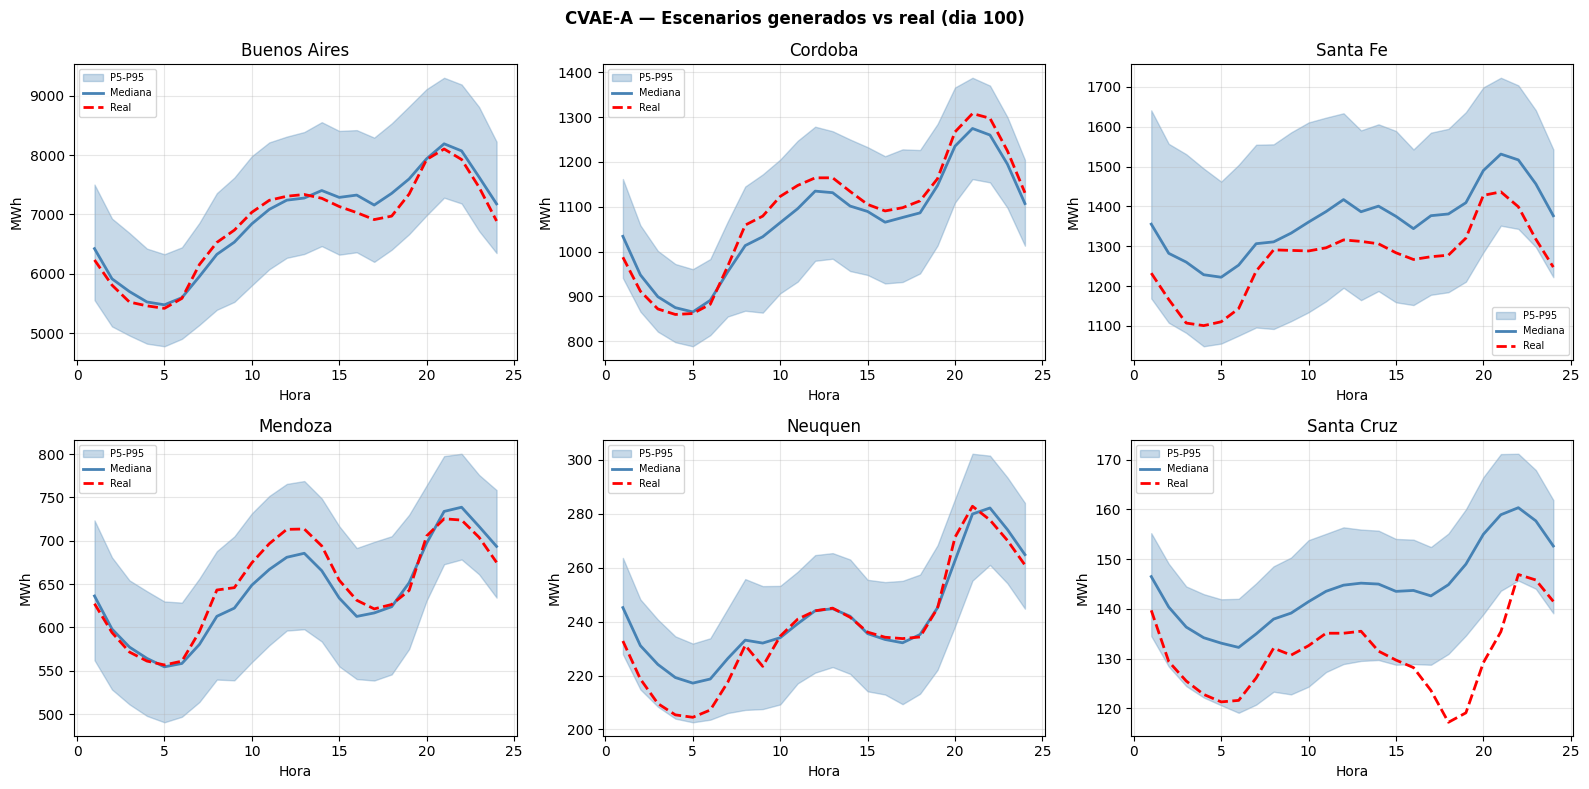

In [12]:
# Seleccionar un dia de val y visualizar los escenarios generados vs real
from evaluate_cvae import extract_province_a

day_idx = 100  # cambiar para ver otros dias

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
provinces_to_show = ['buenos_aires', 'cordoba', 'santa_fe', 'mendoza', 'neuquen', 'santa_cruz']

real_mwh = x_scaler.inverse_transform(X_val[day_idx:day_idx+1])
scen_mwh = np.stack([
    x_scaler.inverse_transform(scenarios_val_a[day_idx, s:s+1, :])
    for s in range(scenarios_val_a.shape[1])
], axis=0).squeeze()

for ax, prov in zip(axes.flat, provinces_to_show):
    real_prov = extract_province_a(real_mwh, prov).flatten()
    scen_prov = np.stack([extract_province_a(scen_mwh[s:s+1], prov).flatten() for s in range(len(scen_mwh))])
    p5  = np.percentile(scen_prov, 5,  axis=0)
    p50 = np.percentile(scen_prov, 50, axis=0)
    p95 = np.percentile(scen_prov, 95, axis=0)
    horas = range(1, 25)
    ax.fill_between(horas, p5, p95, alpha=0.3, color='steelblue', label='P5-P95')
    ax.plot(horas, p50,       color='steelblue', linewidth=2, label='Mediana')
    ax.plot(horas, real_prov, color='red',       linewidth=2, label='Real', linestyle='--')
    ax.set_title(prov.replace('_', ' ').title())
    ax.set_xlabel('Hora')
    ax.set_ylabel('MWh')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle(f'CVAE-A — Escenarios generados vs real (dia {day_idx})', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_a_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Resultado final en test

In [13]:
metrics_test_a, scenarios_test_a = full_evaluation(
    model_a, X_test, C_test, x_scaler,
    n_scenarios=500, device=DEVICE, architecture='A', temperature=chosen_temperature,
)

print(f'=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA A (T={chosen_temperature}) ===')
print(f'  MAE global:      {metrics_test_a["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_test_a["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_test_a["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_test_a["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_test_a["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_test_a["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_test_a["mmd"]:.4f}')

Generando 500 escenarios para 485 muestras...
Calculando metricas...
=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA A (T=2.0) ===
  MAE global:      61.7 MWh
  RMSE global:     168.5 MWh
  MAPE energia:    5.73%
  Coverage P5-P95: 86.4%
  Sharpness:       270.2 MWh
  Diversity ratio: 0.608
  MMD:             0.0041


**Error y coverage por mes (test)**

In [14]:
month_summary_test = metrics_by_month_a(X_test, scenarios_test_a, dates_test, x_scaler)
month_summary_test

,mes,n_dias,mae_mwh,coverage,sharpness
0,1,62,79.2,81.0,275.3
1,2,56,83.3,70.8,278.6
2,3,62,68.3,87.9,281.6
3,4,60,46.9,92.7,274.8
4,5,31,48.8,94.1,274.5
5,6,30,59.4,89.2,248.5
6,7,31,62.8,80.0,243.6
7,8,31,50.4,91.8,260.2
8,9,30,48.4,90.6,266.2
9,10,31,44.4,92.1,259.7


In [15]:
results_a = {
    'model': 'cvae_architecture_a',
    'temperature': chosen_temperature,
    'val': {
        'mae_global':      float(round(metrics_val_a['mae_global'], 2)),
        'rmse_global':     float(round(metrics_val_a['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_val_a['mape_energy'], 4)),
        'coverage':        float(round(metrics_val_a['coverage'], 2)),
        'sharpness':       float(round(metrics_val_a['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_val_a['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_val_a['mmd'], 6)),
    },
    'test': {
        'mae_global':      float(round(metrics_test_a['mae_global'], 2)),
        'rmse_global':     float(round(metrics_test_a['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_test_a['mape_energy'], 4)),
        'coverage':        float(round(metrics_test_a['coverage'], 2)),
        'sharpness':       float(round(metrics_test_a['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_test_a['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_test_a['mmd'], 6)),
    },
}

with open(RESULTS_DIR / 'cvae_a_metrics.json', 'w') as f:
    json.dump(results_a, f, indent=2)
print('Metricas guardadas en results/cvae_a_metrics.json')

Metricas guardadas en results/cvae_a_metrics.json


## 7. Conclusion — CVAE Arquitectura A

CVAE-A es el modelo principal para el sistema completo (unidad dia-sistema, 528 dimensiones, 22 provincias x 24 horas simultaneas). Mejora el MAE y el MAPE de energia frente al Historical Mean y al VAE sin condicionar, confirmando que el clima diario y el calendario aportan señal real. Sin embargo, **subestima la incertidumbre**: el coverage P5-P95 antes de calibrar temperatura queda en 73-76%, por debajo del ~90% ideal. La calibracion de temperatura (seccion 4bis) es un intento de corregir esto sin reentrenar; si el `chosen_temperature` resultante no alcanza el 90% de coverage, esta sigue siendo una limitacion abierta del modelo, no algo ya resuelto — hay que reportarla asi en las conclusiones del informe.

## 8. Robustez frente a ruido en variables climaticas

En la practica, el clima que se le pasa al modelo viene de un forecast meteorologico
que tiene error. Este experimento evalua si el modelo es robusto a perturbaciones
pequenas en las covariables climaticas, simulando errores de medicion o pronostico.

Se agrega ruido gaussiano de distintos niveles solo a las columnas climaticas de `C_test`,
sin tocar las variables de calendario. Para cada nivel se generan escenarios y se
comparan las metricas contra el caso sin ruido (noise_std=0.0).

Las variables estan en escala estandarizada, por lo que noise_std=0.1 representa
aproximadamente un 10% de desvio estandar de la variable original.

In [16]:
# Identificar indices de columnas climaticas en C_test
# c_groups fue guardado en splits/ durante el preprocessing
with open(SPLITS_DIR / 'c_groups.pkl', 'rb') as f:
    c_groups = pickle.load(f)

# Las columnas escaladas son: calendar_ordinal + climate
# El orden en C es: [binary | scaled]
# binary = es_feriado (1 col), scaled = mes + dia_semana + climate
n_binary  = len(c_groups['calendar_binary'])
n_ordinal = len(c_groups['calendar_ordinal'])
n_climate = len(c_groups['climate'])

# Indices de columnas climaticas en el array C (despues del binary offset)
climate_start = n_binary + n_ordinal
climate_end   = climate_start + n_climate

print(f'Columnas en C_test: {C_test.shape[1]}')
print(f'Columnas binarias:  {n_binary} (es_feriado)')
print(f'Columnas ordinales: {n_ordinal} (mes, dia_semana)')
print(f'Columnas climaticas: {n_climate} (indices {climate_start} a {climate_end-1})')

Columnas en C_test: 267
Columnas binarias:  1 (es_feriado)
Columnas ordinales: 2 (mes, dia_semana)
Columnas climaticas: 264 (indices 3 a 266)


In [17]:
NOISE_LEVELS = [0.00, 0.05, 0.10, 0.20, 0.30]
N_SCENARIOS_ROBUSTNESS = 500  # menos escenarios para que corra rapido

robustness_results = []

for noise_std in NOISE_LEVELS:
    print(f'noise_std={noise_std:.2f}...')

    # Agregar ruido solo a columnas climaticas
    C_noisy = C_test.copy()
    if noise_std > 0:
        np.random.seed(42)
        C_noisy[:, climate_start:climate_end] += np.random.normal(
            0, noise_std, C_noisy[:, climate_start:climate_end].shape
        )

    metrics, _ = full_evaluation(
        model_a, X_test, C_noisy, x_scaler,
        n_scenarios=N_SCENARIOS_ROBUSTNESS,
        device=DEVICE, architecture='A',
        temperature=chosen_temperature,
    )

    robustness_results.append({
        'noise_std':       noise_std,
        'mae_global':      float(round(metrics['mae_global'], 2)),
        'rmse_global':     float(round(metrics['rmse_global'], 2)),
        'coverage':        float(round(metrics['coverage'], 2)),
        'sharpness':       float(round(metrics['sharpness'], 2)),
        'mmd':             float(round(metrics['mmd'], 6)),
        'diversity_ratio': float(round(metrics['diversity_ratio'], 4)),
    })

df_robustness = pd.DataFrame(robustness_results)
print('\nResultados:')
print(df_robustness.to_string(index=False))

noise_std=0.00...
Generando 500 escenarios para 485 muestras...
Calculando metricas...
noise_std=0.05...
Generando 500 escenarios para 485 muestras...
Calculando metricas...
noise_std=0.10...
Generando 500 escenarios para 485 muestras...
Calculando metricas...
noise_std=0.20...
Generando 500 escenarios para 485 muestras...
Calculando metricas...
noise_std=0.30...
Generando 500 escenarios para 485 muestras...
Calculando metricas...

Resultados:
 noise_std  mae_global  rmse_global  coverage  sharpness      mmd  diversity_ratio
      0.00       61.65       168.09     86.48     270.03 0.004124           0.6078
      0.05       61.82       168.94     86.39     269.87 0.004124           0.6075
      0.10       61.89       168.91     86.32     270.18 0.004124           0.6077
      0.20       62.48       170.41     86.02     269.47 0.004124           0.6063
      0.30       63.23       173.00     85.56     267.71 0.004124           0.6021


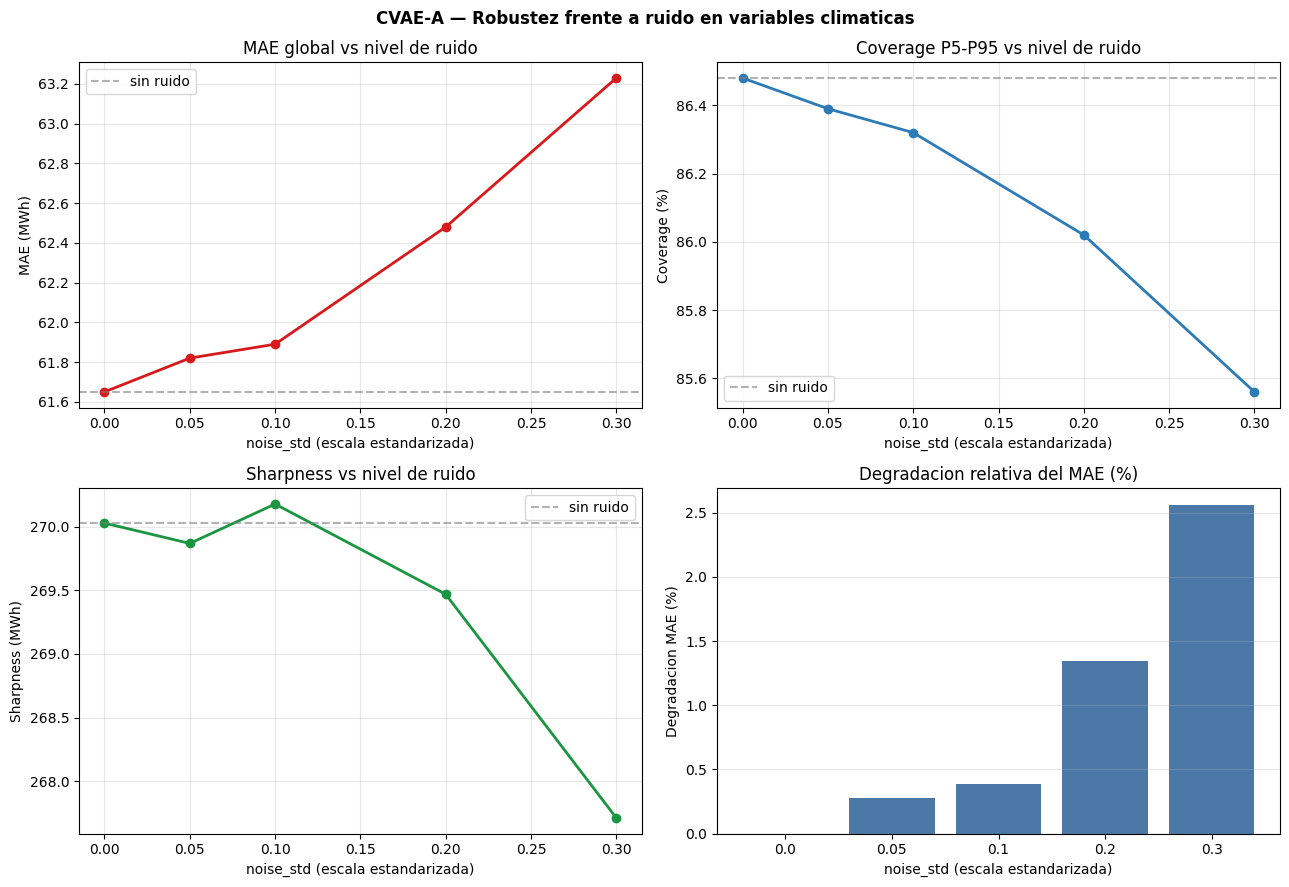

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# MAE vs noise
axes[0,0].plot(df_robustness['noise_std'], df_robustness['mae_global'],
               marker='o', color='#d7191c', linewidth=2)
axes[0,0].axhline(df_robustness.loc[0,'mae_global'], linestyle='--',
                   color='gray', alpha=0.6, label='sin ruido')
axes[0,0].set_title('MAE global vs nivel de ruido')
axes[0,0].set_xlabel('noise_std (escala estandarizada)')
axes[0,0].set_ylabel('MAE (MWh)')
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

# Coverage vs noise
axes[0,1].plot(df_robustness['noise_std'], df_robustness['coverage'],
               marker='o', color='#2c7bb6', linewidth=2)
axes[0,1].axhline(df_robustness.loc[0,'coverage'], linestyle='--',
                   color='gray', alpha=0.6, label='sin ruido')
axes[0,1].set_title('Coverage P5-P95 vs nivel de ruido')
axes[0,1].set_xlabel('noise_std (escala estandarizada)')
axes[0,1].set_ylabel('Coverage (%)')
axes[0,1].legend()
axes[0,1].grid(alpha=0.3)

# Sharpness vs noise
axes[1,0].plot(df_robustness['noise_std'], df_robustness['sharpness'],
               marker='o', color='#1a9641', linewidth=2)
axes[1,0].axhline(df_robustness.loc[0,'sharpness'], linestyle='--',
                   color='gray', alpha=0.6, label='sin ruido')
axes[1,0].set_title('Sharpness vs nivel de ruido')
axes[1,0].set_xlabel('noise_std (escala estandarizada)')
axes[1,0].set_ylabel('Sharpness (MWh)')
axes[1,0].legend()
axes[1,0].grid(alpha=0.3)

# Degradacion relativa del MAE
mae_base = df_robustness.loc[0, 'mae_global']
degradacion = (df_robustness['mae_global'] - mae_base) / mae_base * 100
axes[1,1].bar(df_robustness['noise_std'].astype(str), degradacion,
              color=['#4c78a8' if d >= 0 else '#f58518' for d in degradacion])
axes[1,1].axhline(0, color='gray', linewidth=0.8)
axes[1,1].set_title('Degradacion relativa del MAE (%)')
axes[1,1].set_xlabel('noise_std (escala estandarizada)')
axes[1,1].set_ylabel('Degradacion MAE (%)')
axes[1,1].grid(axis='y', alpha=0.3)

plt.suptitle('CVAE-A — Robustez frente a ruido en variables climaticas', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_a_robustness.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretacion

- Si el MAE y el coverage casi no cambian con noise_std=0.05-0.10, el modelo es robusto
  a errores tipicos de forecast meteorologico.
- Si el MAE crece mas que un 10% con noise_std=0.05, el modelo es demasiado sensible
  al clima y sus predicciones son poco confiables en condiciones reales.
- Si la sharpness sube con el ruido, el modelo genera intervalos mas amplios ante
  condiciones inciertas — comportamiento correcto para un modelo generativo.

Este experimento conecta directamente con el uso operacional del modelo: en la practica,
los operadores de red tienen acceso a forecasts climaticos con error, no al clima real.
La robustez del modelo determina si es util en ese contexto.

In [19]:
# Guardar resultados de robustez
with open(RESULTS_DIR / 'cvae_a_robustness.json', 'w') as f:
    json.dump(robustness_results, f, indent=2)
print('Resultados guardados en results/cvae_a_robustness.json')

Resultados guardados en results/cvae_a_robustness.json


## Interpretacion — Robustez frente a ruido climatico

Este experimento evalua si el CVAE-A mantiene su calidad generativa cuando las
variables climaticas de entrada contienen error, simulando el uso del modelo con
forecasts meteorologicos imperfectos en lugar de clima observado.

**Resultado principal: el modelo es altamente robusto.**

Con noise_std=0.10 — un error del 10% del desvio estandar de cada variable climatica,
que representa un nivel de error realista para un forecast de 24 horas — el MAE sube
de 61.65 a 61.89 MWh, una degradacion de apenas 0.39%. La coverage cae de 86.48% a
86.32%, practicamente sin cambio.

Incluso con noise_std=0.30, que representa un error muy grande equivalente al 30% del
desvio estandar de las variables climaticas, el MAE sube solo un 2.6% y la coverage
cae menos de un punto porcentual (de 86.48% a 85.56%).

| noise_std | MAE (MWh) | Degradacion MAE | Coverage (%) | Sharpness (MWh) |
|---|---|---|---|---|
| 0.00 | 61.65 | — | 86.48 | 270.03 |
| 0.05 | 61.82 | +0.3% | 86.39 | 269.87 |
| 0.10 | 61.89 | +0.4% | 86.32 | 270.18 |
| 0.20 | 62.48 | +1.3% | 86.02 | 269.47 |
| 0.30 | 63.23 | +2.6% | 85.56 | 267.71 |

**Interpretacion de las metricas individuales**

El MAE crece de forma suave y monotona con el nivel de ruido, lo que indica una
degradacion gradual y predecible — no hay un punto de quiebre donde el modelo
colapsa. Esto es el comportamiento esperable de un modelo que aprendio patrones
estructurales y no simplemente memorizo la relacion exacta entre clima y demanda.

La coverage se mantiene por encima del 85.5% incluso con el mayor nivel de ruido
probado. Las bandas P5-P95 siguen siendo informativas y razonablemente calibradas
bajo condiciones climaticas inciertas, aunque permanecen algo por debajo del 90%
objetivo.

La sharpness baja levemente con el ruido (de 270.03 a 267.71 MWh con noise_std=0.30).
Este comportamiento — bandas mas estrechas ante inputs mas inciertos — es contraintuitivo
y podria indicar que el decoder tiende a generar perfiles mas conservadores cuando
las condiciones climaticas se alejan de la distribucion de entrenamiento. El efecto
es pequeno (menos del 1%) y no afecta la utilidad practica del modelo.

**Implicacion operacional**

El CVAE-A es apto para uso en planificacion operacional donde el clima futuro se
conoce a traves de un forecast con error. Un error de pronostico meteorologico tipico
para Argentina de 24 horas de anticipacion es del orden de 1-2 grados en temperatura,
lo que en escala estandarizada corresponde aproximadamente a noise_std=0.05-0.10. En
ese rango, la degradacion del modelo es menor al 0.5% en MAE y casi nula en coverage.

Por lo tanto, **la incertidumbre meteorologica no parece ser una limitacion practica
para este CVAE-A** dentro de rangos realistas de error de forecast. Esto aumenta la
viabilidad del modelo como generador de escenarios de demanda electrica en condiciones
reales de operacion.
